# 04. Quantization: 가중치와 KV dtype은 따로 정하는 결정이다

Part 3은 "block 하나의 byte 수가 용량을 정한다"는 빈칸을 남겼습니다. 이 노트북은 그 byte 수에서 시작합니다. 같은 GPU에 같은 모델을 올려도 **가중치를 몇 비트로 두는가**와 **KV cache를 몇 비트로 두는가**는 서로 다른 설정이고, 서로 다른 몫에 작용합니다. 이 둘을 한 덩어리로 말하는 순간 "FP8이면 메모리가 반으로 준다" 같은 문장이 나오고, 그 문장은 대개 틀립니다.

이 노트북은 속도가 얼마나 빨라지는지를 말하지 않습니다. 이 자료에는 그런 수치를 측정한 출처가 없습니다. 대신 무엇이 줄고 무엇이 줄지 않는지를 식으로 보이고, 방법마다 v0.32.0 문서와 코드가 밝힌 상태를 구분하고, GLM-5.3-Flash 체크포인트와 H200에서의 KV dtype 판단이 **관찰이 아니라 추론**임을 분명히 합니다. 블로그 「Inside vLLM」에는 양자화 절이 없어서 이 노트북은 블로그를 근거로 쓰지 않습니다.

## 학습 목표

- 가중치 양자화(`quantization_config`)와 KV dtype(`--kv-cache-dtype`)이 별개 결정임을 코드 위치로 말한다.
- FP8 KV가 줄이는 것(block의 원시 payload)과 페이지 식에 들어 있지 않은 몫(가중치, activation, CUDA graph 몫)을 구분하고, 그 몫이 KV dtype과 무관한지는 코드로 확인하지 않았음을 말한다.
- `--kv-cache-dtype`의 허용 값과 `--kv-cache-dtype-skip-layers`, 보정 없는 `fp8`의 위험을 문서와 코드에서 찾는다.
- 양자화 방법별 v0.32.0 상태(BitsAndBytes 플러그인, AutoAWQ deprecated, GGUF 실험적)를 구분해 말한다.
- GLM-5.3-Flash 체크포인트의 `quantization_config`를 읽고, H200에서 `--kv-cache-dtype`을 넣지 않는 판단이 어디까지 확인된 것인지 말한다.
- 품질 점검표(Quality Gate)가 vLLM 기능이 아니라 수업의 방법임을 말한다.

## 수업 시간표

| 절 | 내용 | 분 |
|---|---|---:|
| 1 | 두 결정: 가중치와 KV dtype | 6 |
| 2 | FP8이 줄이는 것과 못 줄이는 것 | 7 |
| 3 | KV dtype 값과 보정 | 7 |
| 4 | 가중치 양자화 방법의 현황 | 7 |
| 5 | GLM-5.3-Flash 체크포인트와 H200 | 6 |
| 6 | Quality Gate 점검표 | 4 |
| 7 | 직접 해보기, 확인 질문, 정리 | 3 |

## 호출 규모

모델 호출 0회, 유료 API 호출 0회, 키와 GPU가 필요 없습니다. 모든 숫자는 산수이거나, 소스, 공식 문서, GLM-5.3-Flash 레시피, HF `config.json`에서 옮긴 값이거나, 5절의 `실제 클래스 실행` 기록입니다. 서버를 띄워 본 적은 없습니다.

## 1. 두 결정: 가중치와 KV dtype

**개념.** 모델을 서빙하는 GPU 메모리에는 크게 두 종류의 몫이 있습니다. 하나는 모델 가중치이고, 하나는 요청이 쓰는 KV cache입니다. 양자화라는 말은 두 곳 모두에 쓰이지만 설정이 다릅니다.

- **가중치 양자화.** 체크포인트가 `quantization_config`를 들고 오면 모델을 읽을 때(로드 쪽) 그 형식을 따릅니다. 체크포인트를 만드는 단계에서 이미 정해진 결정입니다.
- **KV dtype.** 서버를 띄울 때 `--kv-cache-dtype`으로 정합니다. 이 값은 `CacheConfig.cache_dtype` 필드에 들어갑니다. 기본값은 `auto`이고, `auto`는 모델 dtype을 쓴다고 코드 주석이 말합니다. 다만 체크포인트가 KV scheme을 선언했으면 `auto`는 그 값을 따릅니다([`vllm/utils/torch_utils.py:512`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/utils/torch_utils.py#L512), [`vllm/model_executor/layers/attention/attention.py:287`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/layers/attention/attention.py#L287)). 플래그를 직접 주면 플래그가 이깁니다.

그래서 "INT4 모델이니 KV도 INT4"는 성립하지 않습니다. 가중치가 INT4여도 KV가 BF16일 수 있고, 가중치가 BF16이어도 KV를 FP8로 둘 수 있습니다. 두 설정은 서로 다른 필드에 있습니다.

**공식 문서.** 양자화 문서의 목록은 AutoAWQ, BitsAndBytes 같은 가중치 방법과 "Quantized KV Cache"를 **별개 항목**으로 나열합니다([`docs/features/quantization/README.md:8`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/quantization/README.md#L8)부터 [`docs/features/quantization/README.md:24`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/quantization/README.md#L24)까지). KV 문서는 `auto`를 "모델의 기본 dtype"이라고 적습니다([`docs/features/quantization/quantized_kvcache.md:39`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/quantization/quantized_kvcache.md#L39)).

**코드.** `cache_dtype`은 `CacheConfig`의 필드이고 기본값이 `"auto"`입니다([`vllm/config/cache.py:122`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L122)). 허용 값은 `CacheDType`이라는 `Literal` 목록 하나로 정해져 있습니다([`vllm/config/cache.py:39`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L39)). 이 목록과 `quantization_config`는 서로 다른 곳에 있습니다.

**직접 관찰.** 아래 셀은 위 대응을 표로 한 번에 놓습니다. 시뮬레이터가 아니라 소스와 공식 문서에서 확인한 사실을 정리한 표입니다.

In [1]:
from vllm_lab import view, kv_math

두결정 = [
    {"결정": "가중치 양자화", "어디서 정하나": "체크포인트의 quantization_config", "언제": "모델 로드(체크포인트 생성 단계에서 이미 정해짐)",
     "줄이는 몫": "가중치", "기본 동작": "체크포인트가 말하는 대로"},
    {"결정": "KV dtype", "어디서 정하나": "--kv-cache-dtype (CacheConfig.cache_dtype)", "언제": "서버를 띄울 때",
     "줄이는 몫": "KV block의 원시 payload", "기본 동작": "auto = 체크포인트의 KV scheme이 있으면 그 값, 없으면 모델 dtype"},
]
view.table(두결정)

,결정,어디서 정하나,언제,줄이는 몫,기본 동작
0,가중치 양자화,체크포인트의 quantization_config,모델 로드(체크포인트 생성 단계에서 이미 정해짐),가중치,체크포인트가 말하는 대로
1,KV dtype,--kv-cache-dtype (CacheConfig.cache_dtype),서버를 띄울 때,KV block의 원시 payload,"auto = 체크포인트의 KV scheme이 있으면 그 값, 없으면 모델 dtype"


**관찰할 것.** 표의 `어디서 정하나` 칸이 두 행에서 완전히 다릅니다. 가중치 양자화 형식이 KV dtype을 저절로 정하지는 않습니다. 예외는 체크포인트가 `quantization_config` 안에 KV scheme까지 선언하고 `--kv-cache-dtype`이 `auto`일 때입니다. `줄이는 몫` 칸도 다릅니다. 이 차이가 2절의 계산에서 숫자로 나옵니다.

## 2. FP8이 줄이는 것과 못 줄이는 것

**개념.** 일반 attention 층에서 block 하나가 차지하는 byte 수는 `num_kv_heads * block_size * (head_size + head_size_v) * dtype 크기`입니다(P2-05). `head_size_v`를 따로 주지 않으면 `head_size`와 같아서, K와 V를 합친 "2배"가 이 식에 들어 있습니다. KV dtype을 FP8로 바꾸면 **마지막 항 `dtype 크기`만** 2 byte에서 1 byte가 됩니다. 나머지 항은 그대로입니다.

**공식 문서.** KV 문서는 FP8 KV가 "memory footprint"를 줄인다고만 적습니다([`docs/features/quantization/quantized_kvcache.md:5`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/quantization/quantized_kvcache.md#L5)). 얼마나 줄이는지, 전체 메모리에서 몇 %인지는 문서에 없습니다.

**코드.** 페이지 크기 식은 [`vllm/v1/kv_cache_interface.py:549`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L549)(state 하나의 byte 수)와 [`vllm/v1/kv_cache_interface.py:552`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L552)(`num_heads * num_states * state_content_size_bytes`)에 있습니다. `fp8`로 시작하는 이름을 양자화로 분류하는 함수는 [`vllm/utils/torch_utils.py:87`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/utils/torch_utils.py#L87)에 있습니다. vLLM이 쓸 전체 예산은 GPU 전체 메모리에 `gpu_memory_utilization`을 곱해 정합니다([`vllm/v1/worker/utils.py:724`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/utils.py#L724)). KV 예산은 그 전체 예산에서 남는 몫입니다. 시작할 때 CUDA graph 메모리를 추정하고([`vllm/v1/worker/gpu_worker.py:700`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu_worker.py#L700), `cudagraph_mode`가 `NONE`이 아닐 때만) 그만큼을 KV 예산에서 뺍니다([`vllm/v1/worker/gpu_worker.py:740`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu_worker.py#L740)). 이 추정을 빼는 동작은 환경 변수 `VLLM_MEMORY_PROFILER_ESTIMATE_CUDAGRAPHS`에 달려 있고 기본값이 켜짐입니다([`vllm/envs.py:2220`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/envs.py#L2220)). 가중치와 activation, CUDA graph 몫은 위 페이지 식에 들어 있지 않습니다. 다만 KV dtype이 이 몫들을 바꾸지 않는다고 코드로 확인하지는 않았습니다.

**이것은 vLLM이 아니라 수업용 모델입니다.** 아래 셀의 `kv_math`는 위 식을 옮겨 적은 산수입니다. 일반 full attention 층(MHA, GQA, MQA)만 다루고, MLA와 recurrent state, TP 샤딩, block 단위 올림, hybrid pool의 padding, `per_token_head` 계열의 scale 저장분은 모델링하지 않았습니다. 숫자는 이 노트북이 정한 가상 모델 `toy-8L`(MHA, 8층, head 8, head 차원 64)이고 GLM-5.3-Flash가 아닙니다. 측정이 아닙니다.

**먼저 예측하세요.** `toy-8L`의 BF16 block 하나(층당, 그리고 8층 합)가 몇 byte인지 계산해 적고, dtype을 `fp8`로 바꾸면 어느 숫자가 얼마가 되는지 적어 보세요.

DeepSeek-V4.1이 main KV를 FP4로 저장하는 사례는 이 노트북의 `fp8`/`bf16` 비교와 다른 정밀도이므로 `02c`의 3절 정밀도 항목에서 봅니다(P7-25).

In [2]:
dtype별 = []
for dtype in ("bfloat16", "fp8"):
    per_layer = kv_math.block_bytes(num_kv_heads=8, head_size=64, dtype=dtype)
    dtype별.append({"dtype": dtype, "num_kv_heads": 8, "head_size": 64, "block_size": 16,
                    "층당 block byte": per_layer, "8층 합 byte": per_layer * 8})
view.table(dtype별)

,dtype,num_kv_heads,head_size,block_size,층당 block byte,8층 합 byte
0,bfloat16,8,64,16,32768,262144
1,fp8,8,64,16,16384,131072


**관찰할 것.** 두 행에서 바뀐 칸은 `dtype`과 byte 수 칸뿐입니다. `num_kv_heads`, `head_size`, `block_size` 칸은 그대로입니다. 이 표에는 가중치나 activation에 해당하는 칸이 아예 없습니다. 식에 들어 있지 않은 몫은 이 식의 결과에 나타나지 않습니다. 실제 서버에서 그 몫이 KV dtype과 무관한지는 이 표로 알 수 없습니다.

In [3]:
rows = []
for head_type, kw in (("MHA", {}), ("GQA", {"num_kv_heads": 2}), ("MQA", {})):
    row = {"head_type": head_type}
    for dtype in ("bfloat16", "fp8"):
        row[dtype + " byte"] = kv_math.raw_kv_bytes(batch=4, layers=8, tokens=1024, head_type=head_type,
                                                    num_heads=8, head_dim=64, dtype=dtype, **kw)
    row["fp8/bf16"] = row["fp8 byte"] / row["bfloat16 byte"]
    rows.append(row)
view.table(rows)

,head_type,bfloat16 byte,fp8 byte,fp8/bf16
0,MHA,67108864,33554432,0.5
1,GQA,16777216,8388608,0.5
2,MQA,8388608,4194304,0.5


위 표는 원식 `2*B*L*T*n*d*b`에 `B=4, L=8, T=1024, d=64`를 넣은 것입니다(D-12). MHA에서 `n`은 head 수, GQA에서는 KV head 수, MQA에서는 1입니다. 세 행 모두 `fp8/bf16` 비가 같습니다. head 구조가 달라도 dtype 항 하나에만 작용하기 때문입니다. 이 식에 TP는 없습니다. 실제 코드에서는 캐시가 TP에 걸쳐 나뉘는 조각 수에 상한 `max_tp_shards`가 있고, 그 너머의 TP rank는 복제본을 듭니다([`vllm/v1/kv_cache_interface.py:513`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L513)). 그래서 GPU 수를 늘려도 rank당 KV가 항상 비례해 줄지는 않습니다.

이 식은 모든 층이 일반 full attention일 때만 맞습니다. GLM-5.3-Flash는 그렇지 않습니다. 다음 셀은 일부러 그 모델에 식을 쓰려 해 봅니다.

In [4]:
# 실패 재현: GLM-5.3-Flash 구조에 원식 2*B*L*T*n*d*b를 쓰려는 시도
try:
    kv_math.raw_kv_bytes(batch=1, layers=1, tokens=1, head_type="glm5next", num_heads=1, head_dim=1)
except kv_math.UnsupportedKVShape as error:
    print("예외 종류:", type(error).__name__)
    print("메시지:", error)
print()
print(kv_math.glm53_kv_note())

예외 종류: UnsupportedKVShape
메시지: head_type='glm5next'은 2*B*L*T*n*d*b로 셀 수 없습니다. 숫자 대신 glm53_kv_note()의 설명을 읽으세요

2*B*L*T*n*d*b는 GLM-5.3-Flash에 쓸 수 없습니다. 이유는 다섯 가지입니다.
1. 선형 attention(KDA) 층은 request당 고정 크기 state라 token 수 T 항이 없습니다 (vllm/models/glm5next/common/kda.py:163).
2. sparse MLA 층은 K와 V를 따로 두지 않고 잠재 벡터 하나만 둡니다. 2배 항이 없고 head 차원은 kv_lora_rank + qk_rope_head_dim입니다 (vllm/models/glm5next/common/attention.py:385).
3. MLA 층마다 indexer cache가 따로 있고 index_kpool token당 state 하나라 T에 비례하되 계수가 다릅니다 (vllm/models/glm5next/common/attention.py:260).
4. tail cache가 request당 고정 크기 링 버퍼로 하나 더 붙습니다 (vllm/models/glm5next/common/attention.py:271).
5. hybrid pool은 group 크기를 맞추려 padding하므로 실제 점유가 이론식보다 클 수 있습니다.
층 구성 숫자는 체크포인트 config에서 읽었습니다(P7-41~P7-43). 층 종류별로 따로 더해야 합니다. 자세한 설명: 02b-KV-Sharing.ipynb의 6절, 02c-KV-Modern-Models.ipynb.


**관찰할 것.** 예외 메시지가 숫자 대신 어디를 읽으라고 가리키는지 보세요. 이 모델의 KV는 식 하나로 셀 수 없어서 이 노트북은 GLM-5.3-Flash의 KV 용량을 숫자로 말하지 않습니다. 층 종류별 계산은 앞에서 본 `02c-KV-Modern-Models.ipynb`에 있고, GPU 메모리 예산에 넣는 추정은 `04b-KV-Operations.ipynb`의 2절에서 합니다.

**먼저 예측하세요.** 이 노트북의 가상 GPU(24 GiB, 비율 0.92)에서 가중치 12 GiB와 기타 2 GiB가 그대로일 때, KV를 FP8로 바꾸면 KV로 쓸 수 있는 token 수는 몇 배가 될까요. 전체 메모리 사용량은 몇 배가 될까요. 두 숫자를 따로 적어 보세요.

In [5]:
GIB = 2**30
common = dict(gpu_total_bytes=24 * GIB, weights_bytes=12 * GIB, other_bytes=2 * GIB, max_model_len=8192)
bf16 = kv_math.capacity_from_budget(block_bytes_all_layers=8 * kv_math.block_bytes(8, 64, "bfloat16"), **common)
fp8 = kv_math.capacity_from_budget(block_bytes_all_layers=8 * kv_math.block_bytes(8, 64, "fp8"), **common)

view.table([
    {"KV dtype": "bfloat16", "KV로 남은 byte": bf16.kv_bytes, "num_blocks": bf16.num_blocks, "token 용량": bf16.capacity_tokens},
    {"KV dtype": "fp8", "KV로 남은 byte": fp8.kv_bytes, "num_blocks": fp8.num_blocks, "token 용량": fp8.capacity_tokens},
])

,KV dtype,KV로 남은 byte,num_blocks,token 용량
0,bfloat16,8675833937,33095,529520
1,fp8,8675833937,66191,1059056


**관찰할 것.** `KV로 남은 byte` 칸은 두 행이 같습니다. 이 toy에서 KV 예산은 "전체 예산에서 가중치와 기타를 뺀 나머지"라서 dtype과 무관합니다. 바뀐 것은 block 하나의 크기이고, 그래서 `num_blocks`와 `token 용량`이 약 두 배가 됩니다. 이것은 "KV에 쓸 수 있는 token 수"가 늘어난 것이지 "전체 메모리 사용량이 줄어든" 것이 아닙니다. 아래 그림은 같은 가상 숫자로 GPU 메모리 구성을 보여 줍니다.

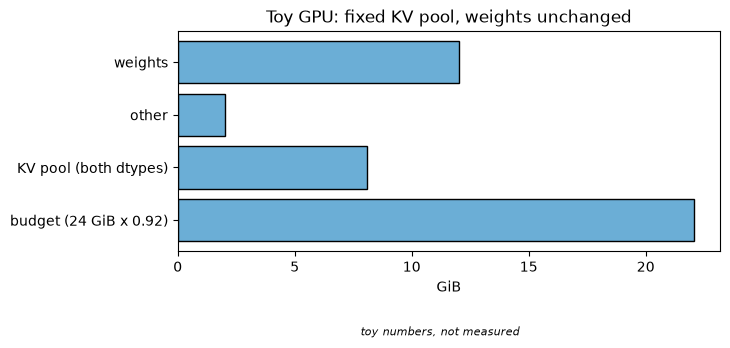

In [6]:
total_budget = bf16.budget_bytes / GIB
fig = view.bar_chart(
    {"weights": 12.0, "other": 2.0, "KV pool (both dtypes)": bf16.kv_bytes / GIB, "budget (24 GiB x 0.92)": total_budget},
    unit="GiB", note="toy numbers, not measured", title="Toy GPU: fixed KV pool, weights unchanged")
fig

**먼저 예측하세요.** 이번에는 반대로, 가중치만 절반(6 GiB)으로 줄었다고 가정하고 KV는 BF16으로 둡니다. KV 용량은 어떻게 변할까요. `기준 대비 용량`이 몇 배가 될지 적으세요. 아래 표에서 확인합니다. 가중치 절반은 두 결정이 독립임을 보이려는 **가정**이고, 실제 어떤 방법이 가중치를 얼마나 줄이는지에 대한 주장이 아닙니다.

In [7]:
def estimate(weights_gib, dtype):
    return kv_math.capacity_from_budget(
        gpu_total_bytes=24 * GIB, weights_bytes=int(weights_gib * GIB), other_bytes=2 * GIB,
        block_bytes_all_layers=8 * kv_math.block_bytes(8, 64, dtype), max_model_len=8192)

cases = [("기준: 가중치 12 GiB, KV bfloat16", 12, "bfloat16"),
         ("가중치만 6 GiB로 (가정), KV bfloat16", 6, "bfloat16"),
         ("KV만 fp8로, 가중치 12 GiB", 12, "fp8"),
         ("둘 다", 6, "fp8")]
base = estimate(12, "bfloat16")
rows = []
for name, weights_gib, dtype in cases:
    e = estimate(weights_gib, dtype)
    rows.append({"경우": name, "KV로 남은 GiB": round(e.kv_bytes / GIB, 2), "block 하나 byte(8층)": 8 * kv_math.block_bytes(8, 64, dtype),
                 "token 용량": e.capacity_tokens, "기준 대비 용량": round(e.capacity_tokens / base.capacity_tokens, 2)})
view.table(rows)

,경우,KV로 남은 GiB,block 하나 byte(8층),token 용량,기준 대비 용량
0,"기준: 가중치 12 GiB, KV bfloat16",8.08,262144,529520,1.00
1,"가중치만 6 GiB로 (가정), KV bfloat16",14.08,262144,922736,1.74
2,"KV만 fp8로, 가중치 12 GiB",8.08,131072,1059056,2.00
3,둘 다,14.08,131072,1845488,3.49


**관찰할 것.** 둘째 행은 `KV로 남은 GiB`가 늘고 `block 하나 byte`는 그대로입니다. 셋째 행은 그 반대입니다. 가중치 쪽 결정은 KV 예산을 키우고, KV dtype 쪽 결정은 block 크기를 줄입니다. 같은 "용량"이 두 경로로 늘 수 있지만 원인이 다르고, 각각 다른 품질 위험을 가집니다.

다음 셀은 서버가 시작할 때 찍는 로그 한 줄의 모양을 두 dtype으로 나란히 놓습니다(D-02의 형식을 `kv_math`가 흉내 낸 문자열입니다). 실제 vLLM은 프로파일링으로 값을 정하며, 이 문자열은 측정이 아닙니다.

In [8]:
print("BF16:", bf16.log_line)
print("FP8 :", fp8.log_line)
print()
print("token 용량 비:", round(fp8.capacity_tokens / bf16.capacity_tokens, 3),
      "| 동시성 비:", round(fp8.max_concurrency / bf16.max_concurrency, 3),
      "| 가중치 몫 비: 1.0 (식에 dtype 항이 없다)")

BF16: GPU KV cache size: 529,520 tokens, Maximum concurrency for 8,192 tokens per request: 64.64x
FP8 : GPU KV cache size: 1,059,056 tokens, Maximum concurrency for 8,192 tokens per request: 129.28x

token 용량 비: 2.0 | 동시성 비: 2.0 | 가중치 몫 비: 1.0 (식에 dtype 항이 없다)


**관찰할 것.** 로그의 `tokens`와 `Maximum concurrency` 두 숫자는 같은 비율로 변하지만, 로그 어디에도 "전체 메모리"는 없습니다. 이 한 줄만 보고 "메모리가 반으로 줄었다"고 읽으면 안 됩니다. 가중치와 activation, CUDA graph 몫을 합친 전체 절감 비율은 이 자료로 계산할 수 없습니다.

**왜 이렇게 설계했나.** 이유는 위 식 자체입니다. `dtype 크기`가 곱해지는 항은 block의 원시 payload 하나뿐이라서, 그 항만 절반이 됩니다([`vllm/v1/kv_cache_interface.py:544-553`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L544-L553)). 가중치와 activation, CUDA graph 몫은 이 식에 없을 뿐이고, KV dtype이 그 값을 바꾸지 않는지는 코드로 확인하지 않았습니다(P4-10, P2-05, P3-08, D-12, D-30). 공식 문서는 "memory footprint 감소"라고만 적고 숫자를 주지 않습니다.

## 3. KV dtype 값과 보정

**개념.** `--kv-cache-dtype`에 줄 수 있는 값은 문서가 설명하는 것보다 코드가 허용하는 것이 훨씬 많습니다. 설명이 없는 값을 "검증된 선택지"로 오해하지 않는 것이 이 절의 목표입니다. 또 FP8 KV를 쓸 때 스케일을 어떻게 얻는지가 품질을 좌우합니다.

**공식 문서.** KV 문서는 `auto`, `fp8_e4m3`(CUDA 11.8+와 ROCm), `fp8_e5m2`(CUDA 11.8+)를 설명합니다([`docs/features/quantization/quantized_kvcache.md:39`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/quantization/quantized_kvcache.md#L39), [`docs/features/quantization/quantized_kvcache.md:40`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/quantization/quantized_kvcache.md#L40), [`docs/features/quantization/quantized_kvcache.md:41`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/quantization/quantized_kvcache.md#L41)). 일반 `fp8`은 예시 코드에서 보입니다([`docs/features/quantization/quantized_kvcache.md:29`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/quantization/quantized_kvcache.md#L29)). 보정 없이 쓰면 모든 스케일이 1.0이라고 합니다([`docs/features/quantization/quantized_kvcache.md:25`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/quantization/quantized_kvcache.md#L25)). 데이터셋으로 보정하는 llm-compressor 경로를 **권장**으로 표기합니다([`docs/features/quantization/quantized_kvcache.md:18`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/quantization/quantized_kvcache.md#L18)에서 per-attention-head 스케일이 이 경로를 요구한다고 적고, 권장 표기는 [`docs/features/quantization/quantized_kvcache.md:92`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/quantization/quantized_kvcache.md#L92)). 특정 층을 건너뛰는 플래그는 [`docs/features/quantization/quantized_kvcache.md:43`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/quantization/quantized_kvcache.md#L43)부터 설명합니다.

**코드.** `CacheDType` 목록은 [`vllm/config/cache.py:39`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L39)부터이고, `fp8`이 `fp8_e4m3`과 같다는 주석은 [`vllm/config/cache.py:123`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L123)에 있습니다. 건너뛸 층을 받는 필드는 [`vllm/config/cache.py:166`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L166)이고 CLI 등록은 [`vllm/engine/arg_utils.py:1384`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L1384)입니다. 실제로 층을 건너뛰는 분기는 [`vllm/model_executor/layers/attention/attention.py:299`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/layers/attention/attention.py#L299)부터이고 건너뛴 층의 dtype을 `auto`로 되돌립니다. 보정 없이 양자화 dtype을 쓰면 "proper scaling factor 없이는 정확도가 떨어질 수 있다"는 정보 로그가 나옵니다([`vllm/config/cache.py:364`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L364)). 이 로그는 오류가 아니라 안내입니다.

런타임 스케일 옵션 `calculate_kv_scales`는 v0.32.0의 `CacheConfig`와 `arg_utils.py`에 없습니다. 소스 전체에서 이 이름은 주석 한 곳에만 남아 있고, 그 주석은 Kimi K3 모델에 관한 것입니다([`vllm/models/kimi_k3/nvidia/mla.py:465`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/kimi_k3/nvidia/mla.py#L465)). 옛 예제의 `--calculate-kv-scales`는 따라 하지 않습니다. 런타임에 스케일을 계산하는 것은 `*_per_token_head` dtype입니다. 이 dtype을 고르면 "Dynamic per-token-head scales will be computed at runtime"이라는 정보 로그가 나옵니다([`vllm/config/cache.py:353`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L353)). `fp8`의 스케일을 런타임에 계산한다는 뜻이 아닙니다. 언제 지워졌는지는 이 소스 트리만으로 알 수 없으므로 시점을 쓰지 않습니다(D-26은 미확인입니다).

**직접 관찰.** 먼저 허용 값 표입니다. 이 목록은 소스 v0.32.0의 `CacheDType`을 읽어 옮긴 것이고, `설명 있음` 칸은 공식 KV 문서가 해당 값을 설명하는지입니다.

In [9]:
허용값 = [
    ("auto", "있음", "체크포인트의 KV scheme이 있으면 그 값, 없으면 모델 dtype(기본값)"),
    ("float16", "없음", ""), ("bfloat16", "없음", ""),
    ("fp8", "있음(예시)", "코드 주석: fp8 = fp8_e4m3"),
    ("fp8_e4m3", "있음", "CUDA 11.8+, ROCm"),
    ("fp8_e5m2", "있음", "CUDA 11.8+"),
    ("fp8_inc", "없음", "코드 주석: Intel Gaudi"),
    ("fp8_ds_mla", "없음", ""), ("nvfp4_ds_mla", "없음", ""),
    ("turboquant_k8v4 등 turboquant_* 4종", "없음", ""),
    ("ultraquant_4bit", "없음", ""),
    ("int4_per_token_head / int8_per_token_head / fp8_per_token_head", "없음", ""),
    ("nvfp4 / nvfp4_4over6", "없음", ""),
]
표 = [{"값": v, "KV 문서 설명": doc, "메모": note,
       "이 노트북의 lab이 byte 수를 아는가": "예" if v in kv_math.DTYPE_BYTES else "아니오"} for v, doc, note in 허용값]
view.table(표)

,값,KV 문서 설명,메모,이 노트북의 lab이 byte 수를 아는가
0,auto,있음,"체크포인트의 KV scheme이 있으면 그 값, 없으면 모델 dtype(기본값)",아니오
1,float16,없음,,예
2,bfloat16,없음,,예
3,fp8,있음(예시),코드 주석: fp8 = fp8_e4m3,예
4,fp8_e4m3,있음,"CUDA 11.8+, ROCm",예
5,fp8_e5m2,있음,CUDA 11.8+,예
6,fp8_inc,없음,코드 주석: Intel Gaudi,아니오
7,fp8_ds_mla,없음,,아니오
8,nvfp4_ds_mla,없음,,아니오
9,turboquant_k8v4 등 turboquant_* 4종,없음,,아니오


**관찰할 것.** `KV 문서 설명` 칸이 `있음`인 값은 `auto`, `fp8`, `fp8_e4m3`, `fp8_e5m2` 넷뿐입니다. 코드의 목록에는 그 외에 설명이 없는 값이 더 있고, 수업은 그것들을 효과가 검증된 선택지처럼 제시하지 않습니다. 마지막 칸이 `아니오`인 값은 이 노트북의 산수 도구가 byte 수를 모르는 값이라는 뜻일 뿐, 그 값이 쓸 수 없다는 뜻이 아닙니다.

다음 셀은 보정 경로를 문서와 코드 근거와 함께 정리합니다.

In [10]:
보정 = [
    {"경로": "보정 없음(kv_cache_dtype=fp8)", "스케일": "모두 1.0", "안내": "정확도 하락 가능성을 알리는 정보 로그", "문서의 태도": "기본 경로"},
    {"경로": "llm-compressor 데이터셋 보정", "스케일": "보정 데이터로 추정", "안내": "per-attention-head 스케일은 Flash Attention 백엔드에서 이 경로가 있어야 함", "문서의 태도": "권장"},
    {"경로": "런타임 계산 옵션 calculate_kv_scales", "스케일": "-", "안내": "v0.32.0 CacheConfig와 arg_utils.py에 없음", "문서의 태도": "언급 없음"},
    {"경로": "per_token_head dtype (int4, int8, fp8)", "스케일": "런타임에 token·head별로 계산", "안내": "cache.py의 정보 로그가 런타임 계산을 적음", "문서의 태도": "언급 없음"},
]
view.table(보정)

,경로,스케일,안내,문서의 태도
0,보정 없음(kv_cache_dtype=fp8),모두 1.0,정확도 하락 가능성을 알리는 정보 로그,기본 경로
1,llm-compressor 데이터셋 보정,보정 데이터로 추정,per-attention-head 스케일은 Flash Attention 백엔드에서 이 경로가 있어야 함,권장
2,런타임 계산 옵션 calculate_kv_scales,-,v0.32.0 CacheConfig와 arg_utils.py에 없음,언급 없음
3,"per_token_head dtype (int4, int8, fp8)",런타임에 token·head별로 계산,cache.py의 정보 로그가 런타임 계산을 적음,언급 없음


**관찰할 것.** 세 번째 행의 `안내` 칸은 "없음"입니다. 이 노트북은 그 옵션이 언제 사라졌는지 말하지 않습니다. 네 번째 행의 런타임 계산은 옵션이 아니라 `per_token_head` dtype을 고른 경우에만 해당하고, `fp8`에는 해당하지 않습니다. 같은 문서가 스케일 계산 방식이 "세 가지"라고 쓰는데 번호가 붙은 항목은 둘뿐이라는 점은 아래 `문서와 코드가 다를 때` 표에서 다룹니다.

문서는 보정이 필요한 이유를 적지 않습니다. 보정 없는 경로는 스케일이 모두 1.0이라고만 쓰고([`:25`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/quantization/quantized_kvcache.md#L25)), 데이터셋 보정을 정확도와 품질 쪽으로 권장합니다([`:33`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/quantization/quantized_kvcache.md#L33), [`:94`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/quantization/quantized_kvcache.md#L94)). 코드 로그는 scaling factor 없이는 정확도가 떨어질 수 있다고 적습니다([`vllm/config/cache.py:364`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L364)). 값 분포와 FP8 표현 범위가 어긋날 수 있다는 설명은 수업의 해석입니다(P4-09). 다음 셀은 `--kv-cache-dtype-skip-layers`가 하는 일을 **장난감**으로 보입니다. 층 8개 중 두 층이 sliding window라고 **가정**하고, 문서의 `sliding_window` 예시처럼 그 층들을 건너뛰면 dtype이 어떻게 달라지는지 봅니다.

In [11]:
# 가정: toy-8L의 2번, 5번 층이 sliding window. 실제 모델의 층 구성이 아니다.
layer_kinds = {i: ("sliding_window" if i in (2, 5) else "full") for i in range(8)}

def per_layer_dtype(skip):
    # attention.py의 분기 규칙을 옮긴 교육용 모델: 종류 이름 또는 층 번호가 skip에 있으면 auto(= 모델 dtype)
    return {i: ("auto->bfloat16" if (kind in skip or str(i) in skip) else "fp8") for i, kind in layer_kinds.items()}

rows = []
for label, skip in (("skip 없음", set()), ("skip: sliding_window", {"sliding_window"}), ("skip: 층 번호 0", {"0"})):
    dtypes = per_layer_dtype(skip)
    total = sum(kv_math.block_bytes(8, 64, "bfloat16" if d.startswith("auto") else "fp8") for d in dtypes.values())
    rows.append({"옵션": label, "fp8로 남은 층": sum(d == "fp8" for d in dtypes.values()),
                 "8층 block byte 합": total, "전부 bfloat16 대비": round(total / (8 * kv_math.block_bytes(8, 64, "bfloat16")), 3)})
view.table(rows)

,옵션,fp8로 남은 층,8층 block byte 합,전부 bfloat16 대비
0,skip 없음,8,131072,0.500
1,skip: sliding_window,6,163840,0.625
2,skip: 층 번호 0,7,147456,0.562


**관찰할 것.** 건너뛴 층이 많을수록 `전부 bfloat16 대비` 비율이 1에 가까워집니다. 민감한 층을 보호하는 대가는 절감 폭입니다. 이 셀의 규칙은 [`vllm/model_executor/layers/attention/attention.py:299`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/layers/attention/attention.py#L299)의 분기를 단순화한 교육용 모델이며 vLLM이 실행한 결과가 아닙니다.

### 문서와 코드가 다를 때

| 문서가 말하는 것 | 코드가 말하는 것 | 근거 |
|---|---|---|
| KV 문서는 `kv_cache_dtype` 값으로 `auto`, `fp8_e4m3`, `fp8_e5m2`(와 예시의 `fp8`)만 설명한다. | `CacheDType`은 `float16`, `bfloat16`, `fp8_inc`, `fp8_ds_mla`, `turboquant_*`, `*_per_token_head`, `nvfp4` 등 훨씬 많은 값을 허용한다([`vllm/config/cache.py:39`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L39)). 코드가 맞다. 다만 설명 없는 값은 효과가 검증됐다는 뜻이 아니다. | P4-03, D-29 |
| KV 문서는 스케일 계산 방식이 "세 가지"라고 쓰지만 번호가 붙은 항목은 둘(기본 스케일 1.0, llm-compressor 보정)이다([`docs/features/quantization/quantized_kvcache.md:23`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/quantization/quantized_kvcache.md#L23)). | 코드에는 `calculate_kv_scales`가 없다. 문서에서 지워진 세 번째 항목이 그것이라는 추정은 가능하지만 추정이다. 지금 따라야 할 것은 둘이다. | P4-07, P4-08 |
| PDF는 runtime `calculate_kv_scales`가 "v0.28에서 제거됐다"고 쓴다. | 현재 버전에 없다는 것은 확인된다. 시점은 이 소스 트리에 이력이 없어 확인되지 않는다. | D-26(미확인) |

**왜 이렇게 설계했나.** 문서는 보정이 필요한 이유를 적지 않고 권장만 합니다([`:33`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/quantization/quantized_kvcache.md#L33), [`:94`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/quantization/quantized_kvcache.md#L94)). 값 분포와 표현 범위 이야기는 수업의 해석입니다. PDF의 "v0.28에서 제거"는 시점을 확인하지 못해 D-26(미확인)으로 남겨 둡니다.

## 4. 가중치 양자화 방법의 현황

**개념.** 가중치 양자화 방법은 많습니다. 방법마다 필요한 하드웨어, 보정 필요 여부, 그리고 v0.32.0에서 얼마나 지원되는지가 다릅니다. 이 절은 문서가 밝힌 상태까지만 말합니다. 어느 방법이 더 빠르거나 정확한지는 말하지 않습니다.

**공식 문서.** 지원 형식 목록은 [`docs/features/quantization/README.md:10`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/quantization/README.md#L10)부터입니다. 방법별로 문서가 직접 적은 상태는 다음과 같습니다.

- AutoAWQ: 라이브러리가 deprecated이고 llm-compressor의 AWQ 예제를 권장합니다([`docs/features/quantization/auto_awq.md:3`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/quantization/auto_awq.md#L3)).
- GPTQModel: INT4 또는 INT8 GPTQ 모델을 만들고 `Marlin`, `Machete` 커널을 활용할 수 있다고 합니다([`docs/features/quantization/gptqmodel.md:3`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/quantization/gptqmodel.md#L3)).
- BitsAndBytes: 보정이 필요 없고, 지원은 외부 플러그인 `vllm-bnb-plugin`이 제공합니다. 쓰기 전에 플러그인을 설치합니다([`docs/features/quantization/bnb.md:3`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/quantization/bnb.md#L3)).
- GGUF: 문서가 "매우 실험적이고 최적화가 덜 되었으며 다른 기능과 호환되지 않을 수 있다"고 쓰고 현재로서는 메모리 사용량을 줄이는 방법으로 쓸 수 있다고 적습니다([`docs/features/quantization/gguf.md:4`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/quantization/gguf.md#L4)). 지원은 외부 플러그인 `vllm-gguf-plugin`으로 옮겨졌고 쓰기 전에 설치합니다([`gguf.md:7`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/quantization/gguf.md#L7)).
- LLM Compressor FP8 W8A8: 문서는 Ada Lovelace, Hopper, Blackwell GPU에서 W8A8을 지원한다고 적습니다([`docs/features/quantization/llm_compressor/fp8.md:4`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/quantization/llm_compressor/fp8.md#L4)). 같은 문서는 메모리와 처리량 개선 수치를 적고 있지만([`docs/features/quantization/llm_compressor/fp8.md:6`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/quantization/llm_compressor/fp8.md#L6)) 측정 조건이 그 줄에 없어서 이 노트북은 수치를 옮기지 않습니다(P4-14).
- ModelOpt: NVFP4 체크포인트를 `quantization="modelopt_fp4"`로 씁니다([`docs/features/quantization/modelopt.md:19`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/quantization/modelopt.md#L19)).

**코드.** 양자화 구현은 `vllm/model_executor/layers/quantization/` 아래에 모듈로 있습니다. 소스 v0.32.0의 디렉터리를 읽어 확인한 목록에는 `auto_awq.py`, `auto_gptq.py`, `fp8.py`, `mxfp4.py`, `modelopt.py`, `torchao.py`, `experts_int8.py` 등이 있고 **bitsandbytes 모듈은 없습니다**(디렉터리 목록 확인, D-27의 시점 부분은 미확인). 이것은 BitsAndBytes가 본체 밖의 플러그인이라는 문서와 일치합니다. 다만 지원 하드웨어 표에는 아직 `bitsandbytes` 행이 남아 있습니다([`docs/features/quantization/README.md:75`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/quantization/README.md#L75)). MXFP4용 Marlin 커널은 `vllm/model_executor/kernels/linear/mxfp4/` 아래에 있습니다.

**직접 관찰.** 아래 표는 위 문장들을 방법별로 묶은 것입니다.

In [12]:
방법 = [
    {"방법": "LLM Compressor (FP8 W8A8, INT4 W4A16, INT8 등)", "v0.32.0 상태": "문서의 시작점으로 안내됨", "주의": "FP8 W8A8은 Ada Lovelace, Hopper, Blackwell. 문서의 개선 수치는 조건 불명이라 인용하지 않음", "근거": "P4-12, P4-14"},
    {"방법": "GPTQModel", "v0.32.0 상태": "문서에 있음", "주의": "INT4/INT8. Marlin, Machete 커널을 쓸 수 있다고 문서가 말함", "근거": "P4-13"},
    {"방법": "AutoAWQ", "v0.32.0 상태": "라이브러리 deprecated(문서)", "주의": "llm-compressor의 AWQ 예제를 권장", "근거": "P4-13"},
    {"방법": "BitsAndBytes", "v0.32.0 상태": "외부 플러그인 vllm-bnb-plugin 설치 필요", "주의": "보정 필요 없음. 본체 내장이 아님", "근거": "P4-16, D-27(미확인: 시점)"},
    {"방법": "GGUF", "v0.32.0 상태": "매우 실험적(문서). 외부 플러그인 vllm-gguf-plugin 설치 필요", "주의": "다른 기능과 호환되지 않을 수 있음. 메모리 절감 용도", "근거": "P4-17"},
    {"방법": "ModelOpt / NVFP4", "v0.32.0 상태": "문서에 있음", "주의": "GLM-5.3-Flash의 NVFP4 변형은 Blackwell이 필요. H200(Hopper)에는 맞지 않음", "근거": "P4-15"},
    {"방법": "그 밖", "v0.32.0 상태": "Intel Neural Compressor, 온라인 양자화, Quark, TorchAO, FP8 ViT", "주의": "이 노트북은 다루지 않음", "근거": "P4-12"},
]
view.table(방법)

,방법,v0.32.0 상태,주의,근거
0,"LLM Compressor (FP8 W8A8, INT4 W4A16, INT8 등)",문서의 시작점으로 안내됨,"FP8 W8A8은 Ada Lovelace, Hopper, Blackwell. 문서의 개선 수치는 조건 불명이라 인용하지 않음","P4-12, P4-14"
1,GPTQModel,문서에 있음,"INT4/INT8. Marlin, Machete 커널을 쓸 수 있다고 문서가 말함",P4-13
2,AutoAWQ,라이브러리 deprecated(문서),llm-compressor의 AWQ 예제를 권장,P4-13
3,BitsAndBytes,외부 플러그인 vllm-bnb-plugin 설치 필요,보정 필요 없음. 본체 내장이 아님,"P4-16, D-27(미확인: 시점)"
4,GGUF,매우 실험적(문서). 외부 플러그인 vllm-gguf-plugin 설치 필요,다른 기능과 호환되지 않을 수 있음. 메모리 절감 용도,P4-17
5,ModelOpt / NVFP4,문서에 있음,GLM-5.3-Flash의 NVFP4 변형은 Blackwell이 필요. H200(Hopper)에는 맞지 않음,P4-15
6,그 밖,"Intel Neural Compressor, 온라인 양자화, Quark, TorchAO, FP8 ViT",이 노트북은 다루지 않음,P4-12


**관찰할 것.** `v0.32.0 상태` 칸의 문장은 전부 **문서가 밝힌 상태**이고, 칸 어디에도 "더 빠르다"나 "더 정확하다"가 없습니다. `근거` 칸의 `D-27(미확인: 시점)`은 PDF가 말한 "v0.28부터"라는 시점이 소스에서 확인되지 않는다는 뜻입니다. 플러그인 방식이라는 사실 자체는 확인됩니다.

NVFP4는 가중치 쪽 이야기입니다. KV cache의 `nvfp4_ds_mla`도 코드가 SM100(Blackwell) 전용으로 제한하지만([`flashmla_sparse.py:250`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/mla/flashmla_sparse.py#L250)) 그것은 KV 이야기입니다. 두 이야기를 섞지 않습니다.

## 5. GLM-5.3-Flash 체크포인트와 H200

**개념.** 앞의 두 결정을 이 수업의 모델에 대입합니다. 가중치 쪽 결정은 이미 체크포인트에 들어 있습니다. KV 쪽 결정은 서버를 띄우는 사람이 합니다. 그런데 H200에서의 KV dtype 판단은 서버 로그로 확인한 것이 아니라 **코드와 레시피에서 끌어낸 추론**입니다. 이 구분을 놓치면 안 됩니다.

**공식 문서.** 이 모델의 체크포인트 구성은 vLLM 공식 문서에 없고, 모델의 HF `config.json`과 [GLM-5.3-Flash 레시피](https://recipes.vllm.ai/zai-org/GLM-5.3-Flash)에 있습니다.

**체크포인트가 말하는 것.** HF `config.json`을 읽은 결과입니다(P4-18). 아래 표를 보세요.

In [13]:
체크포인트 = [
    {"항목": "quant_method", "값": "fp8", "의미": "가중치가 FP8으로 저장됨"},
    {"항목": "fmt", "값": "e4m3", "의미": "FP8 형식"},
    {"항목": "activation_scheme", "값": "dynamic", "의미": "활성값 스케일은 실행 중에 정함"},
    {"항목": "weight_block_size", "값": "있음(숫자는 이 노트북이 옮기지 않음)", "의미": "block 단위 가중치 스케일"},
    {"항목": "modules_to_not_convert", "값": "attn_mha, attn_mqa, dt_bias, hyper_connection, lm_head, mapping_proj, model.embed_tokens 등 + 층별 hc_attn_* 항목", "의미": "이 모듈들은 양자화에서 제외됨"},
    {"항목": "dtype (같은 config)", "값": "bfloat16", "의미": "KV dtype이 auto일 때 따라갈 모델 dtype의 근거"},
    {"항목": "가중치 크기 (레시피)", "값": "FP8 기본 체크포인트 약 306 GiB", "의미": "런타임과 KV 여유분은 별도. BF16 변형은 약 2배라고 레시피가 적음 (P4-19, R-06)"},
]
view.table(체크포인트)

,항목,값,의미
0,quant_method,fp8,가중치가 FP8으로 저장됨
1,fmt,e4m3,FP8 형식
2,activation_scheme,dynamic,활성값 스케일은 실행 중에 정함
3,weight_block_size,있음(숫자는 이 노트북이 옮기지 않음),block 단위 가중치 스케일
4,modules_to_not_convert,"attn_mha, attn_mqa, dt_bias, hyper_connection, lm_head, mapping_proj, model.embed_tokens 등 + 층별 hc_attn_* 항목",이 모듈들은 양자화에서 제외됨
5,dtype (같은 config),bfloat16,KV dtype이 auto일 때 따라갈 모델 dtype의 근거
6,가중치 크기 (레시피),FP8 기본 체크포인트 약 306 GiB,"런타임과 KV 여유분은 별도. BF16 변형은 약 2배라고 레시피가 적음 (P4-19, R-06)"


**관찰할 것.** `modules_to_not_convert` 행을 보세요. 체크포인트가 FP8이라고 해서 모든 가중치가 FP8인 것은 아닙니다. 또 이 표의 어느 행도 KV cache의 dtype을 정하지 않습니다. `dtype`이 bfloat16이라는 사실은 KV `auto`가 무엇을 따라갈지의 근거일 뿐입니다. 레시피에는 FP8 체크포인트와 BF16 체크포인트의 KV pool 토큰 수를 AMD Instinct 절에서 TP=4, 128K context 조건으로 적은 숫자(14.92M 대 8.87M)가 있습니다. 이것은 **체크포인트(가중치)를 바꾼 비교**이고, 레시피는 두 경우의 KV dtype을 적지 않았습니다. 그래서 이 노트북은 그 비를 "FP8 KV의 이득"으로 쓰지 않습니다. 또 AMD 절의 값이라 H200 값도 아닙니다. 어떻게 잰 값인지는 레시피 문장에 없어 미확인입니다(P4-11(미확인)).

다음은 H200에서 KV dtype을 어떻게 판단했는지의 사슬입니다. **같은 표의 `관찰 여부` 칸을 반드시 읽으세요.**

### H200에서 GLM-5.3-Flash의 KV dtype은 추론이다

아래는 코드와 레시피 문장에서 끌어낸 추론입니다. 기동 로그로 확인한 것이 아니고, 이 자료는 서버를 띄운 적이 없습니다. 수업 Pod는 v0.28.1rc1 dev 빌드로 보고되며(R-01) 이 사슬은 v0.32.0 소스 기준이므로, 수업 서버에 그대로 맞는지도 확인되지 않았습니다.

In [14]:
사슬 = [
    {"번호": 1, "사실": "cache_dtype=auto를 fp8_e4m3으로 바꿔 주는 모델별 설정은 GlmMoeDsaForCausalLM에만 있고, SM10x(Blackwell)일 때뿐이다",
     "출처": "vllm/model_executor/models/config.py:43-55, 등록 :1078", "관찰 여부": "코드 읽기"},
    {"번호": 2, "사실": "Glm5Next* 아키텍처는 MODELS_CONFIG_MAP에 없다(파일 안 Glm5Next grep 0건)",
     "출처": "vllm/model_executor/models/config.py:1063", "관찰 여부": "코드 읽기(부재 확인)"},
    {"번호": 3, "사실": "따라서 Hopper SM90의 Glm5Next에서 auto는 코드상 자동으로 FP8이 되지 않고 모델 dtype(config상 bfloat16)을 따른다. 체크포인트 쪽 경로도 막혀 있다: quant_method가 fp8이라 KV scheme을 읽지 않는다",
     "출처": "번호 2의 부재 확인 + vllm/config/cache.py:122-123 + vllm/utils/torch_utils.py:457-530 + vllm/model_executor/layers/quantization/fp8.py:92-101 + P4-18", "관찰 여부": "추론(기동 로그로 확인 안 함)"},
    {"번호": 4, "사실": "FLASHMLA_SPARSE 백엔드는 head_size 512를 SM90에서 auto/bfloat16/float16/fp8_ds_mla일 때만 받고 일반 fp8은 거절한다",
     "출처": "vllm/v1/attention/backends/mla/flashmla_sparse.py:219-248", "관찰 여부": "코드 읽기"},
    {"번호": 5, "사실": "FLASHINFER_MLA_SPARSE_SM90 백엔드는 허용 KV dtype 목록에 auto, bfloat16, fp8, fp8_e4m3을 두고, SM90 전용이며, 모듈 설명이 GLM-5.3-Flash NoPE와 SM90의 FP8 E4M3 KV를 지원한다고 적는다. head_size 512이면 SM90 sparse 후보 맨 앞에 놓인다. 번호 4와 부딪친다: 일반 fp8을 SM90에서 받는 코드 경로가 있다. 이 백엔드가 서버에서 실제로 골라지고 동작하는지는 실행하지 않아 확인하지 못했다. 다른 백엔드(TRITON 등)는 읽지 않았다",
     "출처": "vllm/v1/attention/backends/mla/flashinfer_mla_sparse_sm90.py:3-9,148-153 (SM90 전용 :189-190, 요구 조건 :205-223), vllm/platforms/cuda.py:142-144", "관찰 여부": "코드 읽기(동작은 확인 못 함)"},
    {"번호": 6, "사실": "레시피: Hopper는 이 모델에서 FP8 KV cache를 지원하지 않으며 BF16 KV로 돌려야 한다",
     "출처": "레시피의 Prefill/Decode disaggregation 절 (그 절 제목이 single node, TP4 + TP4인 PD 배치의 문장이라 PD를 쓰지 않는 서빙에도 같은지는 확인이 필요하다). 번호 5의 코드 경로와 어긋난다", "관찰 여부": "레시피 문장(코드와 충돌)"},
    {"번호": 7, "사실": "레시피의 --kv-cache-dtype fp8 예시는 GB200(Blackwell) 예시다. 4xH200 TP4는 KV offloading 검증 기록으로만 나온다",
     "출처": "레시피의 FP8 with TP4 and MTP on one GB200 tray 절, KV cache offloading 절 (R-07)", "관찰 여부": "레시피 문장"},
    {"번호": 8, "사실": "결론: 4xH200에서는 --kv-cache-dtype을 넣지 않는다(기본 auto = BF16 KV). 레시피의 fp8 줄은 H200 명령에서 뺀다. 근거는 레시피 문장(번호 6)과 H200에서 FP8 KV를 돌린 기록이 없다는 점이다. 코드가 막아서가 아니다",
     "출처": "번호 3, 5, 6, 7을 합친 판단", "관찰 여부": "추론이며 관찰 아님"},
]
import pandas as pd
with pd.option_context("display.max_colwidth", None):
    display(view.table(사슬))

,번호,사실,출처,관찰 여부
0,1,"cache_dtype=auto를 fp8_e4m3으로 바꿔 주는 모델별 설정은 GlmMoeDsaForCausalLM에만 있고, SM10x(Blackwell)일 때뿐이다","vllm/model_executor/models/config.py:43-55, 등록 :1078",코드 읽기
1,2,Glm5Next* 아키텍처는 MODELS_CONFIG_MAP에 없다(파일 안 Glm5Next grep 0건),vllm/model_executor/models/config.py:1063,코드 읽기(부재 확인)
2,3,따라서 Hopper SM90의 Glm5Next에서 auto는 코드상 자동으로 FP8이 되지 않고 모델 dtype(config상 bfloat16)을 따른다. 체크포인트 쪽 경로도 막혀 있다: quant_method가 fp8이라 KV scheme을 읽지 않는다,번호 2의 부재 확인 + vllm/config/cache.py:122-123 + vllm/utils/torch_utils.py:457-530 + vllm/model_executor/layers/quantization/fp8.py:92-101 + P4-18,추론(기동 로그로 확인 안 함)
3,4,FLASHMLA_SPARSE 백엔드는 head_size 512를 SM90에서 auto/bfloat16/float16/fp8_ds_mla일 때만 받고 일반 fp8은 거절한다,vllm/v1/attention/backends/mla/flashmla_sparse.py:219-248,코드 읽기
4,5,"FLASHINFER_MLA_SPARSE_SM90 백엔드는 허용 KV dtype 목록에 auto, bfloat16, fp8, fp8_e4m3을 두고, SM90 전용이며, 모듈 설명이 GLM-5.3-Flash NoPE와 SM90의 FP8 E4M3 KV를 지원한다고 적는다. head_size 512이면 SM90 sparse 후보 맨 앞에 놓인다. 번호 4와 부딪친다: 일반 fp8을 SM90에서 받는 코드 경로가 있다. 이 백엔드가 서버에서 실제로 골라지고 동작하는지는 실행하지 않아 확인하지 못했다. 다른 백엔드(TRITON 등)는 읽지 않았다","vllm/v1/attention/backends/mla/flashinfer_mla_sparse_sm90.py:3-9,148-153 (SM90 전용 :189-190, 요구 조건 :205-223), vllm/platforms/cuda.py:142-144",코드 읽기(동작은 확인 못 함)
5,6,레시피: Hopper는 이 모델에서 FP8 KV cache를 지원하지 않으며 BF16 KV로 돌려야 한다,"레시피의 Prefill/Decode disaggregation 절 (그 절 제목이 single node, TP4 + TP4인 PD 배치의 문장이라 PD를 쓰지 않는 서빙에도 같은지는 확인이 필요하다). 번호 5의 코드 경로와 어긋난다",레시피 문장(코드와 충돌)
6,7,레시피의 --kv-cache-dtype fp8 예시는 GB200(Blackwell) 예시다. 4xH200 TP4는 KV offloading 검증 기록으로만 나온다,"레시피의 FP8 with TP4 and MTP on one GB200 tray 절, KV cache offloading 절 (R-07)",레시피 문장
7,8,결론: 4xH200에서는 --kv-cache-dtype을 넣지 않는다(기본 auto = BF16 KV). 레시피의 fp8 줄은 H200 명령에서 뺀다. 근거는 레시피 문장(번호 6)과 H200에서 FP8 KV를 돌린 기록이 없다는 점이다. 코드가 막아서가 아니다,"번호 3, 5, 6, 7을 합친 판단",추론이며 관찰 아님


**관찰할 것.** `관찰 여부` 칸에 "관찰"이라고 쓸 수 있는 행이 있는지 찾아 보세요. 코드 읽기와 레시피 문장은 서버가 실제로 어떤 dtype으로 떴는지를 보여 주지 않습니다. 가장 약한 고리는 5번(코드 경로는 있으나 실행하지 않음)과 6번(레시피 문장의 적용 범위)이고, 이 둘은 서로 부딪칩니다.

**부딪치는 두 근거.** 레시피는 Hopper가 이 모델의 FP8 KV cache를 지원하지 않는다고 적습니다. 반대로 `FLASHINFER_MLA_SPARSE_SM90`의 모듈 설명([`flashinfer_mla_sparse_sm90.py:3-9`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/mla/flashinfer_mla_sparse_sm90.py#L3-L9))은 SM90에서 FP8 E4M3 KV를 지원한다고 적고, 허용 목록에도 일반 `fp8`이 있습니다([`vllm/v1/attention/backends/mla/flashinfer_mla_sparse_sm90.py:148-153`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/mla/flashinfer_mla_sparse_sm90.py#L148-L153)). 이 백엔드는 head_size 512에서 SM90 sparse 후보의 맨 앞입니다([`vllm/platforms/cuda.py:142-144`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/platforms/cuda.py#L142-L144)). 서버를 띄워 보지 않았으므로 어느 쪽이 맞는지는 확인하지 못했습니다. 이 수업의 서버는 레시피의 이유로 H200에서 `--kv-cache-dtype`을 넣지 않습니다.

**실제 클래스 실행.** `Day07_new/data/reference_specs.json`(`docs/reference/specs.md:44-50`)에서 GLM main record는 BF16 1024 byte, `fp8` 512 byte, `fp8_ds_mla` 656 byte, `nvfp4_ds_mla` 352 byte였습니다. 층 클래스와 spec 함수를 CPU에서 부른 값이고 backend와 SM 값은 시나리오가 지정했습니다. 그래서 "이 dtype으로 spec이 만들어진다"는 증거이지, 서버가 그 backend를 고르고 동작한다는 증거가 아닙니다.

관련 코드 위치는 다음과 같습니다. 모델별 승격 설정은 [`vllm/model_executor/models/config.py:43`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/models/config.py#L43), 지도는 [`vllm/model_executor/models/config.py:1063`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/models/config.py#L1063), `GlmMoeDsaForCausalLM` 등록은 [`vllm/model_executor/models/config.py:1078`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/models/config.py#L1078), sparse MLA 백엔드의 head 512 조건은 [`vllm/v1/attention/backends/mla/flashmla_sparse.py:219`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/mla/flashmla_sparse.py#L219), `nvfp4_ds_mla`의 SM100 제한은 [`vllm/v1/attention/backends/mla/flashmla_sparse.py:250`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/mla/flashmla_sparse.py#L250)입니다. 코드의 `fp8_ds_mla`도 허용 목록에 있지만 레시피가 BF16 KV를 지시하므로 이 수업은 쓰지 않습니다. NVFP4 변형(`RedHatAI/GLM-5.3-Flash-NVFP4`)은 레시피상 MoE 전문가가 4비트이고 Blackwell이 필요하므로 H200 실습에 쓰지 않습니다.

**왜 이렇게 설계했나.** 레시피 문장과 코드의 부재 확인이 판단 근거의 전부입니다. 서버 기동 로그나 H200에서 FP8 KV를 실제로 시도한 기록은 없습니다. 그래서 이 노트북은 "H200에서 FP8 KV는 안 된다"고도, "코드가 막는다"고도 단정하지 않고 "플래그를 넣지 않는 쪽이 코드와 레시피에 맞는다"까지만 말합니다. 직접 확인하려면 서버 시작 로그에서 선택된 attention 백엔드와 KV dtype을 읽어야 합니다.

## 6. Quality Gate 점검표

**개념.** 양자화를 바꾸면 품질과 지연이 함께 변할 수 있습니다. 바꾼 뒤에 "잘 되는 것 같다"로 끝내지 않으려면 비교 절차가 필요합니다. 아래 점검표는 PDF가 제안한 양자화 전후 비교 아이디어를 수업에서 쓰기 좋게 양식으로 만든 것입니다.

**이것은 vLLM 기능이 아니라 수업의 방법입니다.** v0.32.0 문서와 코드에서 Quality Gate라는 기능은 확인되지 않았습니다(P4-20(미확인)). 점검표를 vLLM이 제공하는 것처럼 말하지 않습니다. 아래 표는 **빈 칸이 있는 양식**이고 수치를 채우지 않았습니다. 어떤 값이 나올지 이 자료는 알지 못합니다.

**직접 관찰.** 지표 이름은 Part 3에서 쓴 `kv_math.metrics_report`와 이어집니다. 서버의 `/metrics`를 부하 전후로 두 번 읽어 `metrics_report(before, after)`에 넣으면 KV 사용률, preempt 수, 지연 히스토그램의 평균 변화가 나옵니다. 아래는 아직 읽은 값이 없는 상태, 즉 빈 양식입니다.

In [15]:
빈양식 = kv_math.metrics_report({}, {})   # 아직 /metrics를 읽지 않았으므로 값은 모두 None
참고 = {row["항목"]: row["이름"] for row in 빈양식}

gate = [
    {"점검": "같은 입력 묶음", "측정 방법": "양자화 전후에 같은 프롬프트 묶음과 같은 샘플링 설정", "전": "(채울 것)", "후": "(채울 것)", "통과 기준(미리 적을 것)": ""},
    {"점검": "품질 지표", "측정 방법": "본인 업무에 맞는 정답 비교 또는 평가 기준", "전": "(채울 것)", "후": "(채울 것)", "통과 기준(미리 적을 것)": ""},
    {"점검": "같은 부하의 지연", "측정 방법": f"{참고['TTFT(서버)']}, {참고['ITL']}, {참고['E2E']}", "전": "(채울 것)", "후": "(채울 것)", "통과 기준(미리 적을 것)": ""},
    {"점검": "KV 사용률", "측정 방법": 참고["KV 사용률"], "전": "(채울 것)", "후": "(채울 것)", "통과 기준(미리 적을 것)": ""},
    {"점검": "preempt 수", "측정 방법": 참고["preemption 누적"], "전": "(채울 것)", "후": "(채울 것)", "통과 기준(미리 적을 것)": ""},
]
print("metrics_report 빈 값 행 수:", len(빈양식), "| 값이 있는 행:", sum(row["값"] is not None for row in 빈양식))
view.table(gate)

metrics_report 빈 값 행 수: 11 | 값이 있는 행: 0


,점검,측정 방법,전,후,통과 기준(미리 적을 것)
0,같은 입력 묶음,양자화 전후에 같은 프롬프트 묶음과 같은 샘플링 설정,(채울 것),(채울 것),
1,품질 지표,본인 업무에 맞는 정답 비교 또는 평가 기준,(채울 것),(채울 것),
2,같은 부하의 지연,"vllm:time_to_first_token_seconds, vllm:inter_token_latency_seconds, vllm:e2e_request_latency_seconds",(채울 것),(채울 것),
3,KV 사용률,vllm:kv_cache_usage_perc,(채울 것),(채울 것),
4,preempt 수,vllm:num_preemptions,(채울 것),(채울 것),


**관찰할 것.** `통과 기준` 칸이 비어 있는 이유는 결과를 보기 **전에** 적어야 하기 때문입니다. 결과를 본 뒤에 기준을 쓰면 기준이 결과에 맞춰집니다. 이 양식은 비교 대상(전과 후)의 입력이 같아야 한다는 조건은 첫 행에, 부하가 같아야 한다는 조건은 셋째 행에 둡니다. 속도 향상은 이 양식을 채운 뒤에야 말할 수 있고, 이 노트북은 채우지 않았으므로 말하지 않습니다.

**왜 이렇게 설계했나.** 이 절은 vLLM의 설계가 아니라 수업의 방법이라서 설계 이유 대신 왜 수업에 넣었는지를 씁니다. 1절부터 5절까지 본 것처럼 양자화는 메모리 몫과 품질 위험을 함께 바꾸는데, 이 자료에는 어떤 속도나 품질 측정치도 없습니다. 따라서 수강생이 자기 모델에서 같은 방식으로 직접 재야 한다는 점을 양식으로 남겼습니다.

### PDF에서는

| PDF 장 | PDF 내용 | 이 노트북 | 어느 쪽이 맞나 |
|---|---|---|---|
| 5장 FP8 KV Cache | `--kv-cache-dtype fp8`와 보정 | 3절 | 일반론은 맞다. D-24: 수업 서버가 Hopper의 이 모델이므로 Hopper 단서를 덧붙이는 쪽이 맞다. 다만 레시피의 `--kv-cache-dtype fp8` 예시는 GB200 예시이고, Hopper에 BF16을 지시하는 문장은 Prefill/Decode disaggregation 절에 있으며, 코드의 SM90 sparse backend 가운데 `FLASHMLA_SPARSE`는 일반 `fp8`을 거절하지만 `FLASHINFER_MLA_SPARSE_SM90`은 허용 목록에 `fp8`을 둔다(5절). 그래서 수업 서버의 KV dtype은 서버 로그를 보기 전에는 미확인이다 |
| 5장 FP8 KV Cache | 건너뛸 층 옵션 | 3절 | D-25: 일치. PDF의 명령은 주석 처리돼 그대로 실행되지 않는다. 문서 예시는 `--kv-cache-dtype-skip-layers sliding_window`다 |
| 5장 최근 변경 | runtime `calculate_kv_scales` 제거 | 3절 | D-26(미확인): 현재 없다는 것만 맞다고 확인된다 |
| 5장 Weight 축소 | BitsAndBytes out-of-tree | 4절 | D-27(미확인): 사실은 맞고 시점은 확인되지 않는다. D-28: 방법 목록은 코드와 일치 |
| 5장 Weight와 KV Quantization | KV dtype을 BF16과 FP8 둘로 표시 | 1절, 3절 | D-29: 문장은 맞다. 코드는 값이 더 많다. 코드 쪽을 따른다 |

## 직접 해보기

### 해보기 1

`toy-8L`의 `num_kv_heads`를 8에서 2(GQA)로 바꿔 다시 계산합니다.

**먼저 예측하세요.** block 하나의 byte 수는 어떻게 변할까요. FP8 대 BF16의 token 용량 비는 변할까요, 그대로일까요. 이유를 한 문장으로 적고 셀을 실행하세요.

In [16]:
num_kv_heads = 2   # 바꾼 값: 8 -> 2 (GQA)

rows = []
for dtype in ("bfloat16", "fp8"):
    e = kv_math.capacity_from_budget(
        gpu_total_bytes=24 * GIB, weights_bytes=12 * GIB, other_bytes=2 * GIB,
        block_bytes_all_layers=8 * kv_math.block_bytes(num_kv_heads, 64, dtype), max_model_len=8192)
    rows.append({"dtype": dtype, "num_kv_heads": num_kv_heads, "block byte(8층)": 8 * kv_math.block_bytes(num_kv_heads, 64, dtype),
                 "num_blocks": e.num_blocks, "token 용량": e.capacity_tokens})
rows[1]["bf16 대비 용량 비"] = round(rows[1]["token 용량"] / rows[0]["token 용량"], 3)
view.table(rows)

,dtype,num_kv_heads,block byte(8층),num_blocks,token 용량,bf16 대비 용량 비
0,bfloat16,2,65536,132382,2118112,-
1,fp8,2,32768,264765,4236240,2.0


### 해보기 2

`gpu_memory_utilization`을 0.92에서 0.85로 바꿔 다시 계산합니다.

**먼저 예측하세요.** KV로 남는 byte는 몇 GiB 줄어들까요. 그 줄어든 양이 dtype에 따라 다를까요. FP8의 이점이 사라질까요.

In [17]:
gpu_memory_utilization = 0.85   # 바꾼 값: 0.92 -> 0.85

rows = []
for dtype in ("bfloat16", "fp8"):
    e = kv_math.capacity_from_budget(
        gpu_total_bytes=24 * GIB, weights_bytes=12 * GIB, other_bytes=2 * GIB,
        block_bytes_all_layers=8 * kv_math.block_bytes(8, 64, dtype), gpu_memory_utilization=gpu_memory_utilization,
        max_model_len=8192)
    rows.append({"dtype": dtype, "비율": gpu_memory_utilization, "KV GiB": round(e.kv_bytes / GIB, 3),
                 "num_blocks": e.num_blocks, "token 용량": e.capacity_tokens})
view.table(rows)

,dtype,비율,KV GiB,num_blocks,token 용량
0,bfloat16,0.85,6.4,26214,419424
1,fp8,0.85,6.4,52428,838848


## 확인 질문

1. "체크포인트가 FP8 모델이니 KV도 FP8이다"가 왜 항상 맞지는 않는지, 언제 맞게 되는지 `quantization_config`와 `cache_dtype`을 들어 설명하세요.
2. FP8 KV로 block 수가 늘 때 2절의 식과 toy 표에서 바뀌는 칸은 무엇이고, 가중치 몫에 대해 이 식으로 말할 수 있는 것과 없는 것은 무엇인지 말하세요.
3. H200에서 왜 `--kv-cache-dtype fp8`을 뺐고, 이 판단의 가장 약한 고리는 무엇인가요.
4. 레시피의 14.92M과 8.87M 토큰 비교를 왜 KV dtype 효과로 말하면 안 되나요.
5. Quality Gate가 vLLM 기능이 아니라면 어디서 어떻게 돌려야 하나요.
6. 보정 없는 `fp8`에서 일어나는 일을 문서와 코드에서 각각 찾아 말하세요.

## 정리

- 가중치 양자화는 체크포인트의 `quantization_config`이고, KV dtype은 `--kv-cache-dtype`(`CacheConfig.cache_dtype`)입니다. 둘은 별개 설정입니다. 다만 체크포인트가 KV scheme을 선언하고 플래그가 `auto`면 체크포인트 값을 따릅니다.
- FP8 KV가 줄이는 것은 block의 원시 payload뿐입니다. 가중치, activation, CUDA graph 몫은 이 식에 없을 뿐 KV dtype과 무관한지는 확인하지 않았고, 전체 절감 비율은 이 자료로 계산할 수 없습니다. 이 노트북은 속도 향상을 말하지 않았습니다.
- 허용 값은 문서가 설명하는 것보다 코드가 더 많습니다. 보정 없는 `fp8`은 스케일이 1.0이고 `calculate_kv_scales`는 v0.32.0에 없습니다. 런타임 스케일은 `*_per_token_head` dtype의 이야기입니다.
- 방법별 상태: AutoAWQ는 deprecated, BitsAndBytes는 외부 플러그인, GGUF는 매우 실험적이고 외부 플러그인(모두 문서가 밝힌 상태)입니다.
- H200의 BF16 KV 판단은 코드와 레시피의 추론이며 관찰이 아닙니다. 레시피(Hopper는 FP8 KV 미지원)와 코드(`flashinfer_mla_sparse_sm90.py`가 SM90 FP8을 허용)가 부딪치는데 실행하지 않아 가리지 못했습니다. Quality Gate는 vLLM 기능이 아니라 수업의 방법입니다.
- 다음 노트북 `04b`로 넘기는 것: 정밀도로 block 하나를 줄이는 법을 봤으니, 이제 그 KV를 용량으로 세고 prefix cache를 GPU 밖 계층까지 지키는 운영을 봅니다. 그 뒤 Part 5는 client 쪽, 즉 Local Model을 Agent에 연결할 때 턴마다 새 요청이 생기고 무엇이 KV 재사용을 깨는지를 봅니다. 참고로 블로그에는 양자화 절이 없어서 이 노트북에는 블로그 읽기 표를 두지 않았습니다.

## 참고한 근거

P1-22, P4-01, P4-02, P4-03, P4-04, P4-05, P4-06, P4-07, P4-08, P4-09, P4-10, P4-12, P4-13, P4-14, P4-15, P4-16, P4-17, P4-18, P4-19, P2-05, P3-08, D-02, D-12, D-24, D-25, D-27, D-28, D-29, D-30, R-01, R-06, R-07, P7-25, P7-41, P7-42, P7-43, 실제 클래스 실행(`docs/reference/specs.md`).

근거 대장(`docs/sources/`)의 미확인 항목: P4-11(미확인), P4-20(미확인), D-26(미확인), D-27(미확인). 이 항목들은 본문에서도 `미확인`을 붙여 썼고, 사실로 쓰지 않았습니다.